# Q4: Corner Detection 

In this question, you will implement Harris corner detection algorithms for given two input images
(Image1.jpg, Image2.jpg).

- Implement Harris Corner Detection algorithm for images given. In this problem, consider the cornerness measure (C) as `[Det(H) - k.Tr(H)]`, where H is the hessian matrix, `Det()` is the determinant, `Tr()` is the trace, and k is a constant `∈[0.02, 0.04]`. Please use non-negative `k = 1/25` as a starting
value and try to optimize it by trying different values and comment about it.
- In the previous question, replace cornerness measure (C) with `λ1λ2−k(λ1+λ2)` and determine the time efficiency of this system and the system in the previous question. Report the time efficiencies, you are supposed to get the same accuracy results but different time complexities

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

In [13]:
img1_input = cv2.imread('img1.png', cv2.IMREAD_GRAYSCALE)
img2_input = cv2.imread('img2.png', cv2.IMREAD_GRAYSCALE)

### Implementing the algorithm now

In [14]:
from scipy.signal.windows import gaussian
def gaussian_kernel(n, std):
    """Returns a nxn gaussian kernel"""
    std_temp = std/np.sqrt(2) #to fix the issue above

    gauss_1d = gaussian(n, std_temp)
    kernel = np.outer(gauss_1d, gauss_1d)
    kernel = kernel / np.sum(kernel) #normalisation
    return kernel

In [15]:
def cross_correlation_2d(img, kernel, pad=True):
    """
    We do cross correlation with this func. using padding to decide if u want to have zero padding
    """
    img_h, img_w = img.shape
    kernel_h, kernel_w = kernel.shape

    if pad:
        pad_top_bot = kernel_h//2
        pad_left_right = kernel_w//2
        output_h, output_w = img_h, img_w
        img = np.pad(array=img,pad_width=(pad_top_bot, pad_left_right), constant_values=0)
    else:
        output_h, output_w = img_h - kernel_h+1, img_w-kernel_w+1
        
    output_img = np.zeros((output_h, output_w))

    for y in range(output_h):  #move down
        for x in range(output_w): #right
            img_piece = img[y:y+kernel_h, x:x+kernel_w]
            mult = np.multiply(img_piece, kernel)
            output_img[y][x] = np.sum(mult)
    
    return output_img

In [16]:
def convolve_2d(img, kernel, pad=True):
    impulse = np.zeros_like(kernel)
    kernel_h, kernel_w = kernel.shape
    impulse[kernel_h//2, kernel_w//2] = 1
    flipped_kernel = cross_correlation_2d(impulse, kernel, pad=True) #impulse is what my img is, need to have it samesize

    output_img = cross_correlation_2d(img, flipped_kernel, pad=pad)

    return output_img

In [17]:
def non_max_suppression(C, window_size=7, threshold_ratio=0.15):
    threshold = threshold_ratio * np.max(C)
    C_sup = np.zeros_like(C)

    offset = window_size // 2
    for i in range(offset, C.shape[0] - offset):
        for j in range(offset, C.shape[1] - offset):
            local_patch = C[i-offset:i+offset+1, j-offset:j+offset+1]
            if C[i, j] == np.max(local_patch) and C[i, j] > threshold:
                C_sup[i, j] = C[i, j]

    return C_sup

## The function with the actual logic of Harris corner detction

In [18]:
def harris_corner_detector(img, k=1.0/25, ksize=3, sigma=1,
                           method=0, window_size=7, threshold_ratio=0.05):
    

    sobelx = np.array([[-1, 0, 1],
                       [-2, 0, 2],
                       [-1, 0, 1]])
    sobely = np.array([[-1, -2, -1],
                       [ 0,  0,  0],
                       [ 1,  2,  1]])

    blur_kernel = gaussian_kernel(ksize, sigma)
    blurred_img = convolve_2d(img, blur_kernel)

    grad_x = convolve_2d(blurred_img, sobelx)
    grad_y = convolve_2d(blurred_img, sobely)

    xx_grad = convolve_2d(grad_x * grad_x, blur_kernel)
    yy_grad = convolve_2d(grad_y * grad_y, blur_kernel)
    xy_grad = convolve_2d(grad_x * grad_y, blur_kernel)

    det_M = (xx_grad * yy_grad) - (xy_grad ** 2)
    trace_M = xx_grad + yy_grad


    if method == 0: #det - trace2
        C = det_M - k * (trace_M**2)  

    elif method == 1: #eigen vals
        temp = np.sqrt(np.maximum(trace_M**2 - 4*det_M, 0))
        lambda1 = (trace_M + temp) / 2
        lambda2 = (trace_M - temp) / 2
        C = (lambda1 * lambda2) - k * ((lambda1 + lambda2) ** 2)
    else:
        raise ValueError("method must be 0 for 'det-trace' or 1 for 'eigen'")

    
    C_sup = non_max_suppression(C, window_size=window_size, threshold_ratio=threshold_ratio) 

    
    rows, cols = np.where(C_sup > 0)

    
    return rows, cols, img, C


In [19]:

rows1_slow, cols1_slow, img1_slow, C1_slow = harris_corner_detector(img1_input, k=0.01, method=1, window_size=3, threshold_ratio=0.005)
rows1_fast, cols1_fast, img1_fast, C1_fast = harris_corner_detector(img1_input, k=0.01, method=0, window_size=3, threshold_ratio=0.005)

rows2_slow, cols2_slow, img2_slow, C2_slow = harris_corner_detector(img2_input, k=0.04, method=1, window_size=7, threshold_ratio=0.15)
rows2_fast, cols2_fast, img2_fast, C2_fast = harris_corner_detector(img2_input, k=0.04, method=0, window_size=7, threshold_ratio=0.15)

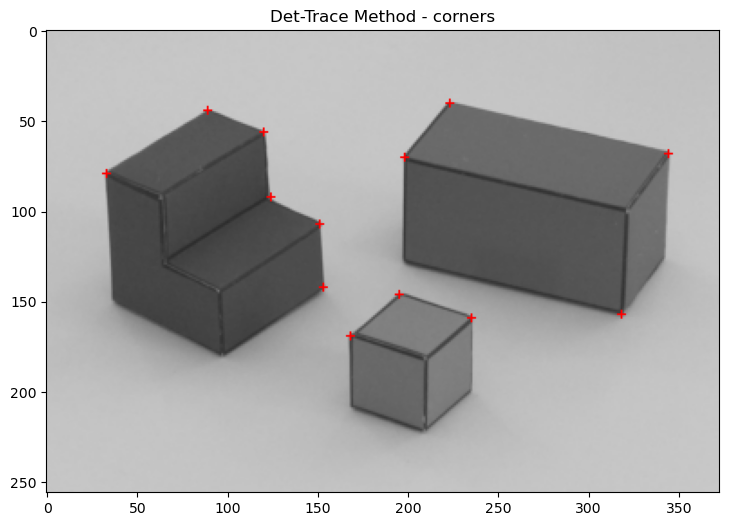

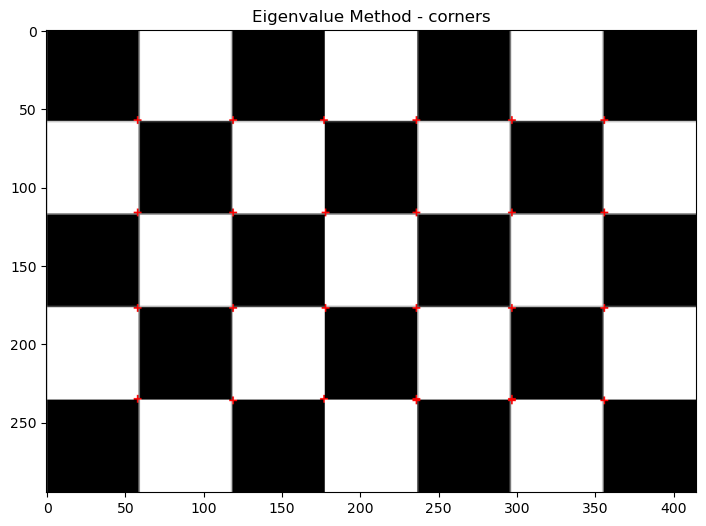

In [20]:

def show_corners(img, rows, cols, title="Corners"):
    corner_img = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
    for r, c in zip(rows, cols):
        cv2.line(corner_img, (c-2, r), (c+2, r), color=(255, 0, 0), thickness=1)
        cv2.line(corner_img, (c, r-2), (c, r+2), color=(255, 0, 0), thickness=1)
    plt.figure(figsize=(10, 6))
    plt.imshow(corner_img)
    plt.title(f"{title} - corners")
    plt.show()

show_corners(img1_input, rows1_fast, cols1_fast, "Det-Trace Method")
show_corners(img2_input, rows2_slow, cols2_slow, "Eigenvalue Method")

In [21]:
import time

start = time.time()
harris_corner_detector(img1_input, k=0.01, method=0, window_size=3, threshold_ratio=0.005)
img1_det_time = time.time() - start

start = time.time()
harris_corner_detector(img1_input, k=0.01, method=1, window_size=3, threshold_ratio=0.005)
img1_eigen_time = time.time() - start

start = time.time()
harris_corner_detector(img2_input, k=0.04, method=0, window_size=7, threshold_ratio=0.15)
img2_det_time = time.time() - start

start = time.time()
harris_corner_detector(img2_input, k=0.04, method=1, window_size=7, threshold_ratio=0.15)
img2_eigen_time = time.time() - start

print(f"Image 1 - Det-Trace: {img1_det_time}s, Eigenvalue: {img1_eigen_time:}s")
print(f"Image 2 - Det-Trace: {img2_det_time}s, Eigenvalue: {img2_eigen_time:}s")

Image 1 - Det-Trace: 1.741424322128296s, Eigenvalue: 1.7530739307403564s
Image 2 - Det-Trace: 2.273480176925659s, Eigenvalue: 2.3304672241210938s


## Conclusion

### k (Cornerness Threshold)
- Purpose: Controls sensitivity to corners
- Lower k means more sensetive and higher means less sensetive
- 3D shapes: k=0.01 
- checkerboard: k=0.04 
- because the shapes image in grayscale becomes very hard to detect corners, while black and white stays same

### method for Cornerness Measure
- Method 0: Det-Trace method
  - Faster
  - Uses determinant and trace of H directly
- Method 1: Eigenvalue method  
  - Slower
  - Computes actual eigenvalues
  - More accurate, but will be slower for larger imgs(here it was faster because we used nupmy broadcasting)

### window size in non maximum suppression
- Size of neighborhood for local maximum detection
- Smaller window size means more corners detected
- Larger window means less corners detected(supress more)
- Image 1: window_size=3 
- Image 2: window_size=7

### Threshold Ratio
- Purpose: fraction of the max corner response that is used to filter weak corners
- lower ratio means we detected all corners, even weak
- high ratio means only strong
- Image 1: threshold_ratio=0.005 (very low, catches faint corners)
- Image 2: threshold_ratio=0.15 (high, only strong checkerboard corners)


notes:
- We had subtle corners in the grayscaled boxes image making corners hard to find. so we used more sensetive parameters
- In the grid image we have strong corners so we used less sensetive parameters to reduce noise